# Partie 3 : Auto-Encodeurs et détection d'anomalies

Dans cette partie, nous entraînons des auto-encodeurs uniquement sur des feuilles saines (train). Une feuille malade doit alors être mal reconstruite : erreur de reconstruction ‖x - x̂‖² > seuil. (Chap. 3)

Tous les choix de (k, modèle) se font sur la validation.

In [18]:
import sys, os
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np, torch
from torch import nn
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score

from src import config as C
from src import data as D
from src.models import build_ae

C.set_seed(42)
dev = C.DEVICE
print(C.describe_env())

Python 3.12.15, torch 2.14.1+cu126, torchvision 0.29.1+cu126
Calcul sur : cuda
GPU : NVIDIA GeForce RTX 2060 with Max-Q Design
CPU : AMD Ryzen 9 4900HS with Radeon Graphics (16 coeurs logiques)


## 1. Données

- Entraînement : feuilles saine du train (images 64x64, pixels dans [0, 1], pas de normalisation car la sortie est une Sigmoid).
- Validation : feuilles saines (pour le seuil) et feuilles malades (pour évaluer la détection).
- Augmentation légère (flips horizontal et vertical) seulement sur le train.
- Tout est chargé en tenseurs (N, 3, 64, 64)

In [19]:
df = D.load_splits()
healthy = C.HEALTHY_CLASS
diseased = [c for c in D.CLASSES if c != healthy]

def load(split, classes):
    """Images 64x64 d'un split -> tenseur (N, 3, 64, 64) dans [0, 1]."""
    d = D.subset(df, split=split, classes=classes)
    imgs = D.load_cache([C.resolve(p) for p in d["path"]], C.AE_SIZE)
    return torch.from_numpy(np.array(imgs)).permute(0, 3, 1, 2).float().div(255).to(dev)

X_train = load("train", [healthy])
X_val_h = load("val", [healthy])
X_val_d = load("val", diseased)
print("Healthy (train) :", tuple(X_train.shape), "| Healthy (val) :", tuple(X_val_h.shape), "| Diseased (val) :", tuple(X_val_d.shape))

Healthy (train) : (1115, 3, 64, 64) | Healthy (val) : (237, 3, 64, 64) | Diseased (val) : (2487, 3, 64, 64)


## 2. Architecture

- Encodeur : 3 convolutions (F=4, S=2, P=1) qui divisent la taille par 2 : 64 → 32 → 16 → 8, puis une couche dense vers **k** (goulot).

- Décodeur symétrique avec des convolutions transposées, Sigmoid en sortie. Perte : MSE entre l'image et sa reconstruction.

In [20]:
print(build_ae(16))
for k in (16, 64, 256):
    print(f"k = {k:3d} : {sum(p.numel() for p in build_ae(k).parameters()):,} parameters")

Sequential(
  (0): Sequential(
    (0): Conv2d(3, 32, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Conv2d(32, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (5): ReLU()
    (6): Conv2d(64, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (7): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (8): ReLU()
    (9): Flatten(start_dim=1, end_dim=-1)
    (10): Linear(in_features=8192, out_features=16, bias=True)
  )
  (1): Sequential(
    (0): Linear(in_features=16, out_features=8192, bias=True)
    (1): Unflatten(dim=1, unflattened_size=(128, 8, 8))
    (2): ConvTranspose2d(128, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (3): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, b

## 3. Étude du goulot k ∈ {16, 64, 256}

L'image fait n = 3x64x64 = 12 288 valeurs. Avec k << n, l'AE doit compresser ; si k se rapproche de n il tend vers l'identité et reconstruit aussi bien les feuilles malades (reconstruction _trop bonne_).

In [21]:
import time

EPOCHS, BATCH, LR = 40, 64, 1e-3

def train_ae(k, noise=0.0):
    """
    Entraine un AE de goulot k sur les feuilles healthy.
      - noise > 0 : AE débruiteur (entrée bruitée, cible propre).
    """
    t0 = time.time()
    model = build_ae(k).to(dev)
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    criterion = nn.MSELoss()
    hist_train, hist_val = [], []
    for ep in range(EPOCHS):
        model.train()
        order = torch.randperm(len(X_train), device=dev)
        total = 0.0
        for i in range(0, len(order), BATCH):
            x = X_train[order[i:i + BATCH]]
            if torch.rand(1) < 0.5: x = x.flip(3)          # flip horizontal
            if torch.rand(1) < 0.5: x = x.flip(2)          # flip vertical
            x_in = (x + noise * torch.randn_like(x)).clamp(0, 1) if noise > 0 else x
            loss = criterion(model(x_in), x)
            opt.zero_grad(); loss.backward(); opt.step()
            total += loss.item() * len(x)
        model.eval()
        with torch.no_grad():
            val = criterion(model(X_val_h), X_val_h).item()    # validation : healthy, entrée propre
        hist_train.append(total / len(X_train)); hist_val.append(val)
        if (ep + 1) % 10 == 0:
            print(f"k={k} epoch {ep + 1}/{EPOCHS}  loss train {hist_train[-1]:.5f}  val {val:.5f}")
    return model, hist_train, hist_val, time.time() - t0     # durée du training

KS = [16, 64, 256]
models, hist, train_time = {}, {}, {}
for k in KS:
    models[k], loss_tr, loss_va, train_time[k] = train_ae(k)
    hist[k] = (loss_tr, loss_va)
    torch.save(models[k].state_dict(), C.CKPT_DIR / f"ae_k{k}.pt")

k=16 epoch 10/40  loss train 0.00812  val 0.00806
k=16 epoch 20/40  loss train 0.00732  val 0.00741
k=16 epoch 30/40  loss train 0.00707  val 0.00745
k=16 epoch 40/40  loss train 0.00686  val 0.00707
k=64 epoch 10/40  loss train 0.00734  val 0.00730
k=64 epoch 20/40  loss train 0.00533  val 0.00528
k=64 epoch 30/40  loss train 0.00455  val 0.00465
k=64 epoch 40/40  loss train 0.00429  val 0.00442
k=256 epoch 10/40  loss train 0.00722  val 0.00738
k=256 epoch 20/40  loss train 0.00497  val 0.00491
k=256 epoch 30/40  loss train 0.00393  val 0.00440
k=256 epoch 40/40  loss train 0.00328  val 0.00383


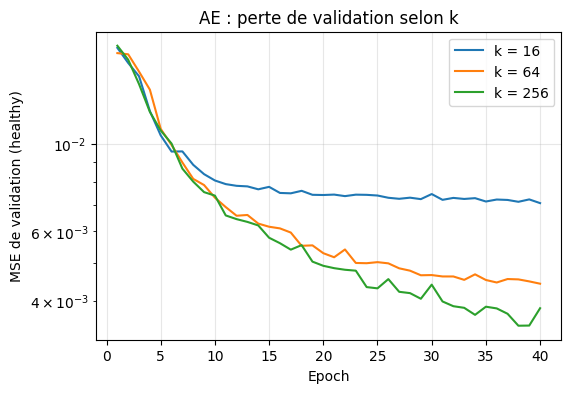

In [22]:
plt.figure(figsize=(6, 4))
for k in KS:
    plt.plot(range(1, EPOCHS + 1), hist[k][1], label=f"k = {k}")
plt.yscale("log"); plt.xlabel("Epoch"); plt.ylabel("MSE de validation (healthy)")
plt.title("AE : perte de validation selon k"); plt.legend(); plt.grid(alpha=.3)
plt.savefig(C.FIG_DIR / "03_ae_courbes_k.png", dpi=150, bbox_inches="tight"); plt.show()

## 4. Reconstructions

- Ligne 1 : originales
- Lignes suivantes : reconstruction pour chaque k. D'abord des feuilles saines de la validation, puis des feuilles malades.

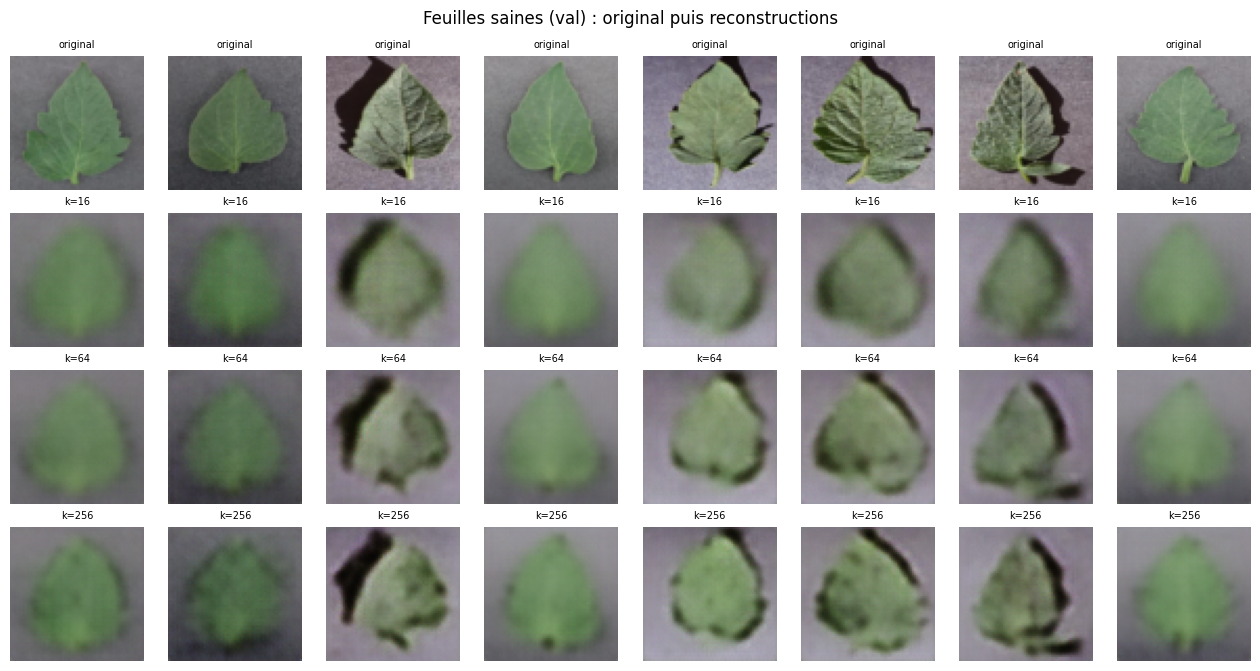

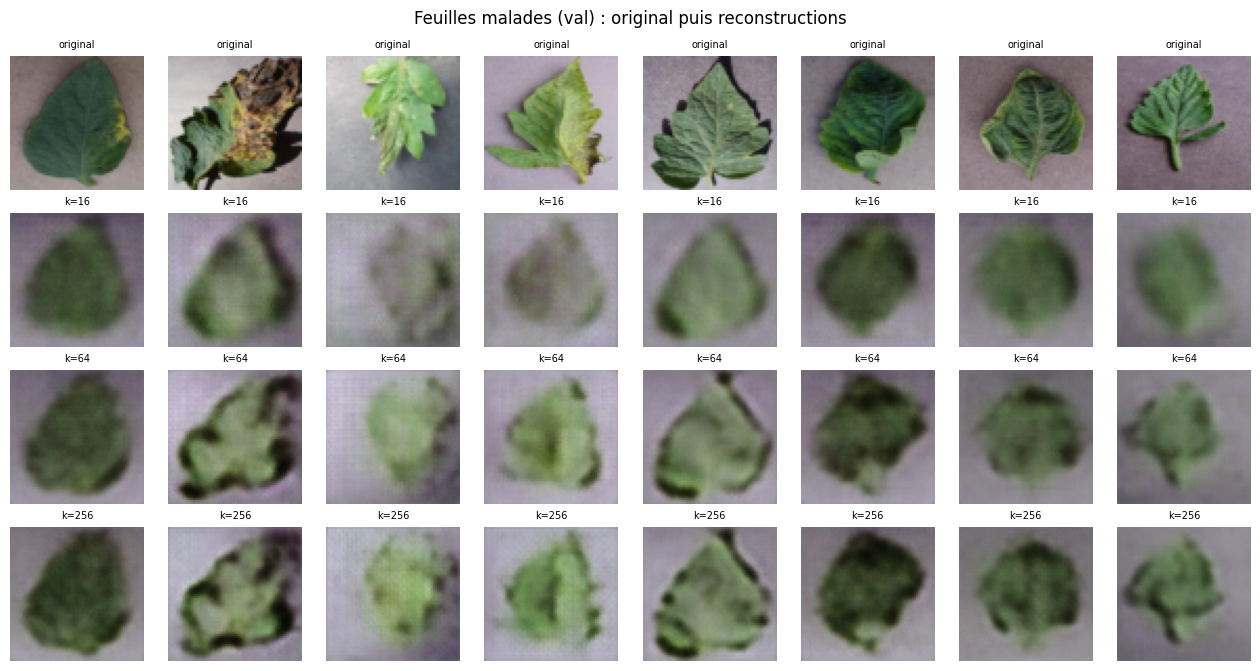

In [23]:
def show_recon(X, title, fname, n=8):
    """Ligne 1 : originales ; lignes suivantes : reconstructions pour chaque k."""
    x = X[np.linspace(0, len(X) - 1, n).astype(int)]
    rows = [("original", x)]
    with torch.no_grad():
        for k in KS:
            rows.append((f"k={k}", models[k].eval()(x)))
    fig, ax = plt.subplots(len(rows), n, figsize=(n * 1.6, len(rows) * 1.7))
    for r, (name, imgs) in enumerate(rows):
        for c in range(n):
            ax[r, c].imshow(imgs[c].permute(1, 2, 0).cpu().numpy()); ax[r, c].axis("off")
            ax[r, c].set_title(name, fontsize=7)
    fig.suptitle(title); plt.tight_layout()
    plt.savefig(C.FIG_DIR / fname, dpi=150, bbox_inches="tight"); plt.show()

show_recon(X_val_h, "Feuilles saines (val) : original puis reconstructions", "03_recon_saines.png")
show_recon(X_val_d, "Feuilles malades (val) : original puis reconstructions", "03_recon_malades.png")

## 5. Erreur de reconstruction : saines vs malades (validation)

Le rapport erreur(malades) / erreur(saines) mesure la capacité de détection : plus il est grand, mieux l'AE sépare les deux populations. On retient le k qui maximise l'**AUROC sur la validation** (jamais sur le test).

In [24]:
@torch.no_grad()
def recon_errors(model, X):
    """Erreur de reconstruction par image : moyenne des pixels de (x - x_hat)^2."""
    model.eval()
    return torch.cat([((model(X[i:i + 256]) - X[i:i + 256]) ** 2).mean(dim=(1, 2, 3))
                      for i in range(0, len(X), 256)]).cpu().numpy()

def auroc(e_healthy, e_diseased):
    """Anomalie = classe positive, score = erreur de reconstruction."""
    y = np.r_[np.zeros(len(e_healthy)), np.ones(len(e_diseased))]
    return roc_auc_score(y, np.r_[e_healthy, e_diseased])

errs, aurocs = {}, {}
print(f"{'k':>5s} {'mse_healthy':>11s} {'mse_diseased':>12s} {'rapport':>8s} {'auroc_val':>10s}")
for k in KS:
    eh, ed = recon_errors(models[k], X_val_h), recon_errors(models[k], X_val_d)
    errs[k], aurocs[k] = (eh, ed), auroc(eh, ed)
    print(f"{k:>5d} {eh.mean():>11.5f} {ed.mean():>12.5f} {ed.mean() / eh.mean():>8.2f} {aurocs[k]:>10.3f}")

K_BEST = max(aurocs, key=aurocs.get)      # choix sur la validation uniquement
print("K_BEST =", K_BEST)

    k mse_healthy mse_diseased  rapport  auroc_val
   16     0.00707      0.01023     1.45      0.634
   64     0.00442      0.00594     1.34      0.610
  256     0.00383      0.00504     1.31      0.613
K_BEST = 16


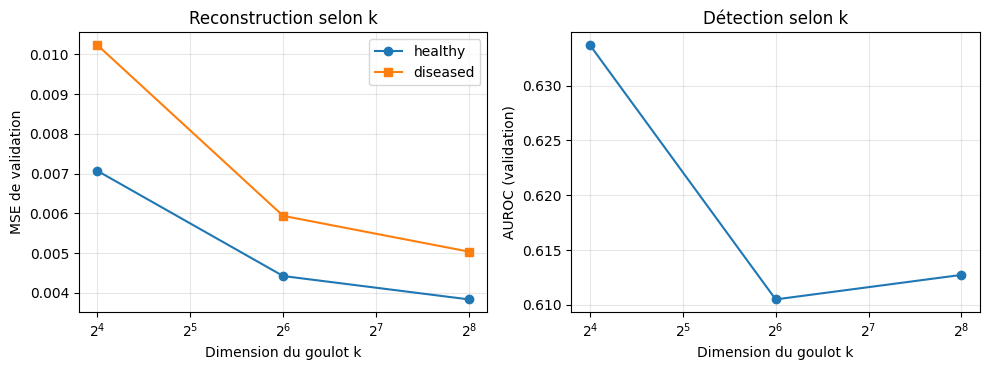

In [25]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
ax[0].plot(KS, [errs[k][0].mean() for k in KS], "o-", label="healthy")
ax[0].plot(KS, [errs[k][1].mean() for k in KS], "s-", label="diseased")
ax[0].set_xscale("log", base=2); ax[0].set_xlabel("Dimension du goulot k"); ax[0].set_ylabel("MSE de validation")
ax[0].set_title("Reconstruction selon k"); ax[0].legend(); ax[0].grid(alpha=.3)
ax[1].plot(KS, [aurocs[k] for k in KS], "o-")
ax[1].set_xscale("log", base=2); ax[1].set_xlabel("Dimension du goulot k"); ax[1].set_ylabel("AUROC (validation)")
ax[1].set_title("Détection selon k"); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.savefig(C.FIG_DIR / "03_mse_auroc_vs_k.png", dpi=150, bbox_inches="tight"); plt.show()

**Interprétation (reconstructions et effet de k)**

- *Reconstructions.* Avec k = 16 (compression 12 288 → 16, soit x768), l'AE ne garde que la couleur et la silhouette : l'image est floue. À k = 64 le contour apparaît, à k = 256 on retrouve les nervures et ombres. C'est le rôle du goulot (Chap. 3) : plus k est petit, plus l'AE doit compresser l'info.

- *Effet de k sur la MSE.* La MSE des feuilles saines baisse avec k (0,0071 → 0,0044 → 0,0038), ce qui est tout a fait logique : plus de capacité, meilleure reconstruction. Celle des feuilles malades baisse aussi (0,0102 → 0,0059 → 0,0050).

- *Effet de k sur la détection.* Le rapport erreur_malades/erreur_saines passe de 1,45 (k = 16) à 1,34 puis 1,31, et l'AUROC de validation de 0,634 à 0,610 puis 0,613. L'écart entre k = 64 et k = 256 (0,003) est négligeable ; ce qui compte est la chute entre k = 16 et k >= 64. Quand k grandit vers n, l'AE tend vers l'identité et reconstruit aussi bien les feuilles malades : c'est la « reconstruction _trop bonne_ » (limite de la compression). On retient donc **k = 16**, choisi a partir de la validation uniquement.

- *Limite.* Même au meilleur k, l'AUROC (0,634) reste proche du hasard soit 0,5. La MSE moyenne est dominée par les grandes zones (feuille, fond, ombres) : une petite lésion pèse peu. Le score mesure en partie la complexité de l'image et le fond, pas la maladie, d'où un risque de biais de fond. Les histogrammes de la section 6 le confirment (distribution des feuilles saines à 2 modes).

- *Convergence.* La perte de validation baisse encore à l'époque 40, surtout pour k = 256 (0,0044 à l'époque 30, 0,0038 à l'époque 40) : l'entraînement n'est pas totalement convergé. Cependant, cela ne change pas le choix de k, puisque k = 16 gagne déjà avec une marge de 0,02 d'AUROC et que des AE plus grands, mieux entraînés, devraient reconstruire encore mieux les malades.

## 6. Variante débruiteuse

Entrée bruitée x̃ = x + N(0, σ²) avec σ = 0,1, cible propre : L = ‖x − g(f(x̃))‖². Le bruit empêche l'AE de recopier l'entrée. On compare à l'AE simple au même k.

In [26]:
dae, _, _, t_dae = train_ae(K_BEST, noise=0.1)
torch.save(dae.state_dict(), C.CKPT_DIR / f"dae_k{K_BEST}.pt")
eh_d, ed_d = recon_errors(dae, X_val_h), recon_errors(dae, X_val_d)
eh_a, ed_a = errs[K_BEST]

print(f"{'model':>18s} {'mse_healthy':>11s} {'mse_diseased':>12s} {'rapport':>8s} {'auroc_val':>10s}")
for name, h, d in [(f"AE k={K_BEST}", eh_a, ed_a), (f"DAE k={K_BEST} s=0,1", eh_d, ed_d)]:
    print(f"{name:>18s} {h.mean():>11.5f} {d.mean():>12.5f} {d.mean() / h.mean():>8.2f} {auroc(h, d):>10.3f}")

k=16 epoch 10/40  loss train 0.00813  val 0.00851
k=16 epoch 20/40  loss train 0.00734  val 0.00759
k=16 epoch 30/40  loss train 0.00709  val 0.00747
k=16 epoch 40/40  loss train 0.00684  val 0.00735
             model mse_healthy mse_diseased  rapport  auroc_val
           AE k=16     0.00707      0.01023     1.45      0.634
    DAE k=16 s=0,1     0.00735      0.01041     1.42      0.630


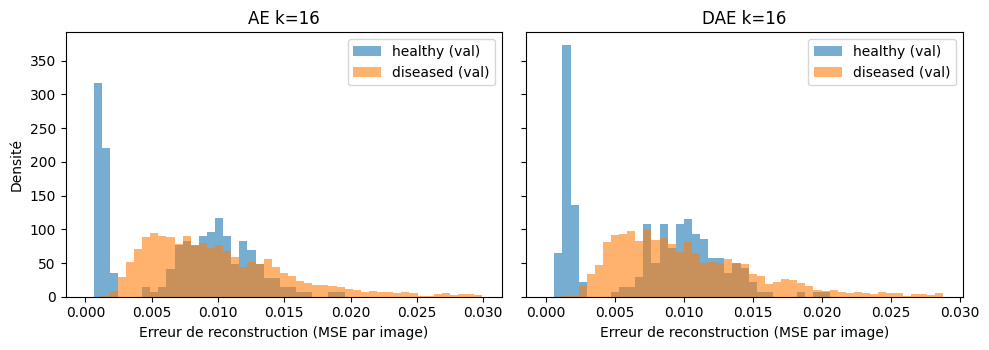

In [27]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for a, title, h, d in [(ax[0], f"AE k={K_BEST}", eh_a, ed_a), (ax[1], f"DAE k={K_BEST}", eh_d, ed_d)]:
    bins = np.linspace(0, np.percentile(np.r_[h, d], 99), 50)
    a.hist(h, bins, alpha=.6, density=True, label="healthy (val)")
    a.hist(d, bins, alpha=.6, density=True, label="diseased (val)")
    a.set_title(title); a.set_xlabel("Erreur de reconstruction (MSE par image)"); a.legend()
ax[0].set_ylabel("Densité")
plt.tight_layout(); plt.savefig(C.FIG_DIR / "03_hist_erreurs_val.png", dpi=150, bbox_inches="tight"); plt.show()

**Interprétation (AE simple vs débruiteur)**

Le débruiteur ne sépare pas mieux que l'AE simple : AUROC de validation 0,630 contre 0,634, rapport 1,42 contre 1,45, pour une MSE des saines un peu plus haute (0,00735 vs 0,00707). Le bruit (σ = 0,1) empêche de recopier l'entrée et devrait forcer l'AE à apprendre la structure de la feuille ; mais à k = 16 le goulot est déjà très contraignant, donc le bruit ajoute peu de régularisation. La différence (0,004 d'AUROC) est trop faible pour conclure à une supériorité de l'un ou l'autre avec une seule graine ; le choix de l'AE simple (validation) est confirmé sur le test (0,628 contre 0,625).

Sur les histogrammes, la distribution des saines a **deux modes** : un pic net vers 0,001–0,002 (feuilles simples, fond uniforme, très bien reconstruites) et une masse vers 0,01 (feuilles sombres, ombrées ou texturées). Les malades se placent surtout entre 0,004 et 0,012 (62 %), avec un mode plus bas que la masse des saines : 43 % des malades ont une erreur inférieure à la médiane des saines (0,0080). Beaucoup de malades sont donc mieux reconstruites que beaucoup de saines. Le score reflète la complexité de l'image plus que la maladie. Le seuil p95 des saines (0,014) tombe dans la queue droite des malades : il garde ~5 % de fausses alarmes mais laisse passer l'essentiel des malades (faux négatifs), le cas coûteux pour le maraîcher (maladie non traitée).

## 7. Seuil de détection (validation)

Règle du cours : une feuille est déclarée **anormale** si ‖x − x̂‖² > seuil. On fixe le seuil au **percentile 95 des erreurs des feuilles saines de la validation** : par construction, environ 5 % des feuilles saines déclenchent une fausse alarme.

Le modèle gardé (AE simple ou débruiteur) est choisi sur l'**AUROC de validation**, jamais sur le test.

In [28]:
import json

thr_ae  = float(np.percentile(eh_a, 95))     # seuil de l'AE simple
thr_dae = float(np.percentile(eh_d, 95))     # seuil de l'AE débruiteur

auc_val = {"ae": auroc(eh_a, ed_a), "dae": auroc(eh_d, ed_d)}
best_name = max(auc_val, key=auc_val.get)                      # choix sur la validation
best_model, thr_best = (models[K_BEST], thr_ae) if best_name == "ae" else (dae, thr_dae)
print(f"seuil AE  : {thr_ae:.5f}  | seuil DAE : {thr_dae:.5f}")
print(f"AUROC val : {auc_val}  ->  modèle gardé : {best_name}")

# False Positives et détection sur la VALIDATION
print(f"val, fausses alarmes (saines > seuil)  : {(eh_a > thr_ae).mean():.3f}  (attendu ~0.05)")
print(f"val, rappel malades (malades > seuil)  : {(ed_a > thr_ae).mean():.3f}")

seuil AE  : 0.01405  | seuil DAE : 0.01431
AUROC val : {'ae': np.float64(0.6337155741501377), 'dae': np.float64(0.629538579516439)}  ->  modèle gardé : ae
val, fausses alarmes (saines > seuil)  : 0.051  (attendu ~0.05)
val, rappel malades (malades > seuil)  : 0.201


## 8. Évaluation sur le test

Le test n'est utilisé **qu'ici**, une seule fois par modèle, avec les seuils fixés ci-dessus.

- **AUROC** : qualité du score indépendamment du seuil (0,5 = hasard, 1 = parfait).
- **Recall des maladies** : part des feuilles malades dépassant le seuil (anomalies détectées). Un faux négatif = maladie non traitée.
- **Taux de False Positives** : part des feuilles saines dépassant le seuil (traitement inutile).

In [29]:
X_test_h = load("test", [healthy])
X_test_d = load("test", diseased)

rows = []
for name, model, thr in [("AE", models[K_BEST], thr_ae), ("DAE", dae, thr_dae)]:
    eh_t, ed_t = recon_errors(model, X_test_h), recon_errors(model, X_test_d)
    rows.append((name, auroc(eh_t, ed_t), (ed_t > thr).mean(), (eh_t > thr).mean()))

print(f"{'model':>8s} {'AUROC':>7s} {'recall_diseased':>15s} {'false_positives':>16s}")
for name, a, rec, fa in rows:
    print(f"{name:>8s} {a:>7.3f} {rec:>15.3f} {fa:>16.3f}")

   model   AUROC recall_diseased  false_positives
      AE   0.628           0.201            0.084
     DAE   0.625           0.194            0.079


In [30]:
# On garde le modèle choisi sur la validation et les fichiers pour les parties suivantes
torch.save(best_model.state_dict(), C.CKPT_DIR / "ae_best.pt")
C.save_json({"model": best_name, "k": K_BEST, "threshold_p95": thr_best,
             "threshold_ae": thr_ae, "threshold_dae": thr_dae,
             "auroc_val": auc_val}, C.RESULTS / "thresholds_ae.json")
print("Saved ae_best.pt and thresholds_ae.json (model :", best_name, ")")

Saved ae_best.pt and thresholds_ae.json (model : ae )


In [31]:
import pandas as pd

def size_mb(model):
    """Taille du state_dict en Mo."""
    return sum(t.numel() * t.element_size() for t in model.state_dict().values()) / 1e6

summary_path = C.RESULTS / "summary.csv"
summary = pd.read_csv(summary_path) if summary_path.exists() else pd.DataFrame()

for (name, a, rec, fa), model, t, mse in [(rows[0], models[K_BEST], train_time[K_BEST], eh_a.mean()),
                                          (rows[1], dae, t_dae, eh_d.mean())]:
    row = {"model": f"{name.lower()}_k{K_BEST}", "part": 3, "k": K_BEST,
           "params": sum(p.numel() for p in model.parameters()), "size_mb": round(size_mb(model), 2),
           "train_time_s": round(t, 1), "mse_healthy_val": mse,
           "auroc_test": a, "recall_diseases_test": rec, "false_alarm_test": fa}
    summary = summary[summary.get("model", pd.Series(dtype=str)) != row["model"]]
    summary = pd.concat([summary, pd.DataFrame([row])], ignore_index=True)

summary.to_csv(summary_path, index=False)
print(summary.tail(2).to_string(index=False))

  model  part  k  params  size_mb  train_time_s  mse_healthy_val  auroc_test  recall_diseases_test  false_alarm_test
 ae_k16     3 16  602067     2.41          21.9         0.007069    0.627681              0.201126          0.083682
dae_k16     3 16  602067     2.41          22.0         0.007349    0.625350              0.193886          0.079498


## 9. Rappel par maladie et cartes d'erreur

- *Question*: Quelles maladies sont mal détectées ?

- *Hypothèse* : celles à petites taches ou faible contraste, car la MSE moyenne est dominée par les grandes zones (feuille et fond) et une petite lésion pèse peu.

disease                 n_test  recall
Bacterial_spot             319    0.01
Mosaic_virus                55    0.02
Spider_mites               251    0.10
Leaf_Mold                  143    0.14
Yellow_Leaf_Curl           804    0.17
Target_Spot                212    0.20
Early_blight               150    0.34
Septoria_leaf_spot         266    0.36
Late_blight                286    0.45


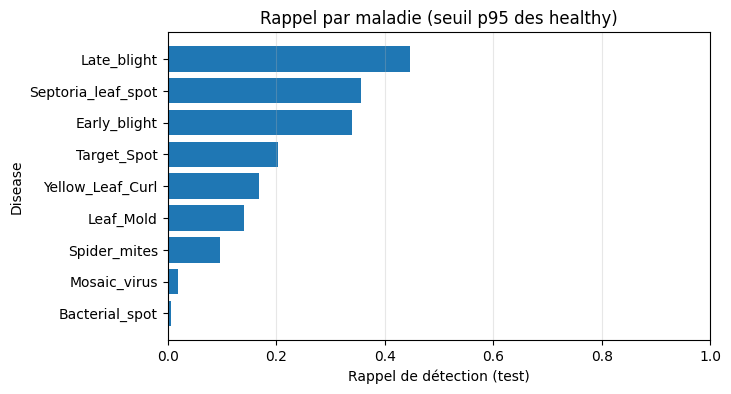

In [32]:
eh_best_t = recon_errors(best_model, X_test_h)
recall, X_by_class = {}, {}
for c in diseased:
    X_by_class[c] = load("test", [c])
    recall[c] = (recon_errors(best_model, X_by_class[c]) > thr_best).mean()

order = sorted(recall, key=recall.get)
print(f"{'disease':<22s} {'n_test':>7s} {'recall':>7s}")
for c in order:
    print(f"{D.short(c):<22s} {len(X_by_class[c]):>7d} {recall[c]:>7.2f}")

plt.figure(figsize=(7, 4))
plt.barh([D.short(c) for c in order], [recall[c] for c in order])
plt.xlabel("Rappel de détection (test)"); plt.ylabel("Disease"); plt.xlim(0, 1)
plt.title("Rappel par maladie (seuil p95 des healthy)"); plt.grid(axis="x", alpha=.3)
plt.savefig(C.FIG_DIR / "03_rappel_par_maladie.png", dpi=150, bbox_inches="tight"); plt.show()

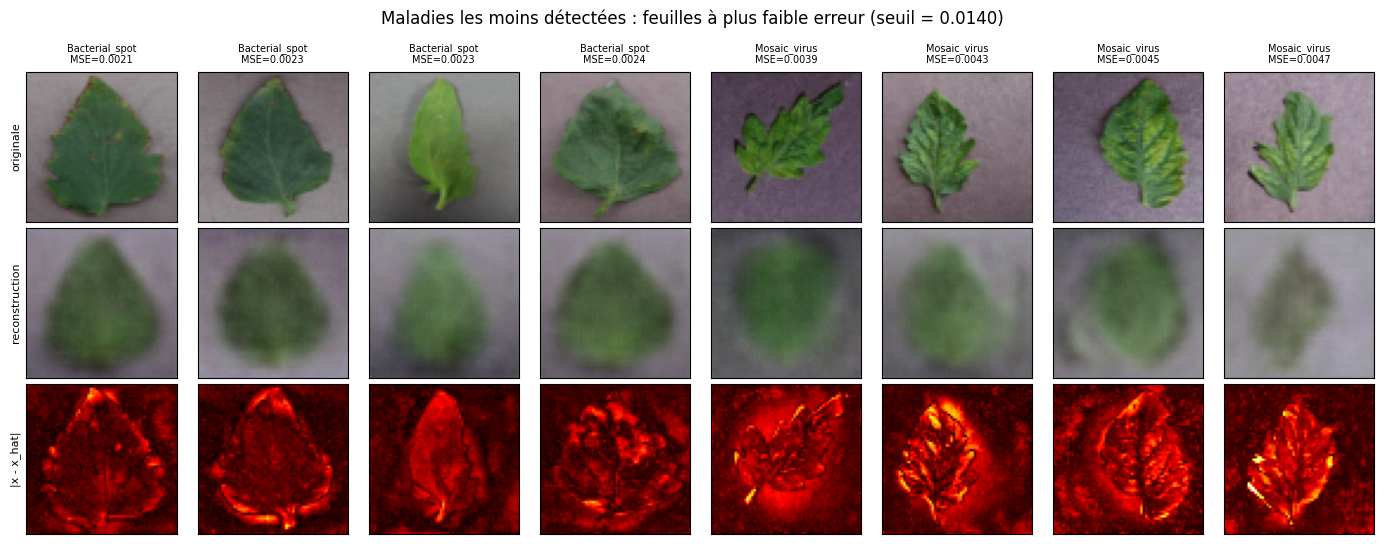

In [33]:
@torch.no_grad()
def error_map(model, x):
    """Carte d'erreur |x - x_hat| moyennée sur les canaux : (N, 64, 64)."""
    model.eval()
    return (model(x) - x).abs().mean(dim=1)

worst = order[:2]                                    # les 2 maladies les moins bien détectées
fig, ax = plt.subplots(3, 8, figsize=(14, 5.5))
for g, c in enumerate(worst):
    e = recon_errors(best_model, X_by_class[c])
    idx = np.argsort(e)[:4]                          # les 4 feuilles les moins bien détectées
    x = X_by_class[c][idx]
    with torch.no_grad():
        x_hat = best_model.eval()(x)
    emap = error_map(best_model, x).cpu().numpy()
    for j in range(4):
        col = g * 4 + j
        ax[0, col].imshow(x[j].permute(1, 2, 0).cpu().numpy())
        ax[1, col].imshow(x_hat[j].permute(1, 2, 0).cpu().numpy())
        ax[2, col].imshow(emap[j], cmap="hot", vmin=0, vmax=0.3)
        ax[0, col].set_title(f"{D.short(c)}\nMSE={e[idx[j]]:.4f}", fontsize=7)
for r, lab in enumerate(["originale", "reconstruction", "|x - x_hat|"]):
    ax[r, 0].set_ylabel(lab, fontsize=8)
for a in ax.ravel():
    a.set_xticks([]); a.set_yticks([])
plt.suptitle(f"Maladies les moins détectées : feuilles à plus faible erreur (seuil = {thr_best:.4f})")
plt.tight_layout(); plt.savefig(C.FIG_DIR / "03_cartes_erreur.png", dpi=150, bbox_inches="tight"); plt.show()

## 10. Piste : erreur maximale locale

Si la MSE moyenne dilue les petites lésions, on peut utiliser comme score le **maximum de l'erreur lissée localement** (moyenne sur des fenêtres 8×8), qui réagit à une tache même petite. Comparaison faite sur l'ensemble de **validation** uniquement.

In [34]:
import torch.nn.functional as F

@torch.no_grad()
def local_max_errors(model, X, win=8):
    """Score = maximum, sur l'image, de l'erreur quadratique moyennée par fenêtres."""
    model.eval()
    out = []
    for i in range(0, len(X), 256):
        x = X[i:i + 256]
        sq = ((model(x) - x) ** 2).mean(dim=1, keepdim=True)          # (N, 1, 64, 64)
        out.append(F.avg_pool2d(sq, win, stride=win // 2).amax(dim=(1, 2, 3)))
    return torch.cat(out).cpu().numpy()

lh, ld = local_max_errors(best_model, X_val_h), local_max_errors(best_model, X_val_d)
print(f"AUROC val, MSE moyenne        : {auc_val[best_name]:.3f}")
print(f"AUROC val, maximum local 8x8  : {auroc(lh, ld):.3f}")

AUROC val, MSE moyenne        : 0.634
AUROC val, maximum local 8x8  : 0.582


## 11. Interprétation (test, seuil, maladies, maximum local)

- *Test.* AE et DAE sont équivalents : AUROC 0,628 et 0,625, rappel des malades 0,201 et 0,194, Faux Positifs 0,084 et 0,079. Le taux de fausses alarmes dépasse les 5 % visés : le seuil est le percentile 95 de seulement 237 feuilles saines de validation, donc d'une douzaine d'images au-dessus du seuil, et il est peu stable. Les feuilles saine du test, ou le simple aléa d'échantillonnage, suffisent à le décaler (5,1 % en validation, 8,4 % sur le test). Les données ne permettent pas de séparer les deux causes.

- *Coût asymétrique* Pour 5 à 8 % de FP, le recall est d'environ 20 % : quatre feuilles malades sur cinq passent sans alerte. Ce n'est pas acceptable pour le maraîcher (car elle traduit la récolte perdue), et un seuil plus bas pour gagner du rappel multiplie les FP, car les distributions se chevauchent largement. À cette étape, l'AE seul ne suffit pas comme détecteur de maladie.

- *Par maladie.* Les moins détectées sont Bacterial_spot (rappel 0,01, n = 319), Mosaic_virus (0,02, n = 55) et Spider_mites (0,10) ; les mieux détectées sont Late_blight (0,45), Septoria_leaf_spot (0,36) et Early_blight (0,34). Hypothèse : Bacterial_spot a des taches peu étendues, noyées dans la MSE moyenne ; Late_blight et Septoria couvrent de plus grandes surfaces. Le rappel global (0,20) est tiré vers le bas par les classes nombreuses et mal détectées (Yellow_Leaf_Curl : n = 804, rappel 0,17).

- *Cartes d'erreur.* Pour les feuilles les moins détectées (Bacterial_spot, Mosaic_virus), l'erreur ne se concentre pas sur les lésions mais sur le **contour de la feuille, les nervures et le fond**. L'AE flou ne reproduit pas ces détails quelques soient la classe, il y a donc un biais de contour et de fond. La MSE médiane de Bacterial_spot (0,0054) et de Mosaic_virus (0,0064) est inférieure à celle des saines (0,0080).

- *Maximum local.* Le score local fait moins bien que la MSE moyenne (AUROC de validation 0,582 contre 0,634) : l'hypothèse « la moyenne dilue les petites lésions » n'est pas confirmée, probablement parce que le maximum local est dominé par les contours et les nervures (hypothèse non vérifiée ici). On garde la MSE moyenne pour la partie 4 ; le maximum local n'est pas évalué sur le test.

- Pour conclure sur cette partie, cet AE n'a vu que des feuilles saines et arrive a détectr les feuilles  avec le critere « anormal », pas « inconnu ». Avec un rappel de 0,20 et 8 % de faux positifs, il ne peut pas servir seul de détecteur d'inconnu d'ou l'interet de le comparer avec l'approche hybride.